<a href="https://colab.research.google.com/github/AffanXR4/praktikum_avd/blob/main/Praktikum_AVD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Latihan 1 : Eksplorasi Data & Statistika Deskriptif dengan Pandas**

In [ ]:
import pandas as pd

# Memuat dataset
df = pd.read_csv('penjualan_nusantaramart.csv')

# Eksplorasi awal
print(df.head())  # lihat 5 baris pertama
print(df.info())  # tipe data & jumlah data kosong
print(df.describe())  # ringkasan statistik

# Rata-rata total pembelian per kategori produk
rata_kategori = df.groupby('kategori_produk')['total'].mean()
print(rata_kategori.sort_values(ascending=False))

   order_id     tanggal    kategori_produk        nama_produk   wilayah  \
0      1146  2026-01-03           Olahraga        Matras Yoga    Malang   
1      1166  2026-01-05            Fashion       Celana Jeans  Surabaya   
2      1190  2026-01-05          Kesehatan   Masker Medis Box  Semarang   
3      1219  2026-01-08  Makanan & Minuman  Kopi Kemasan 200g   Bandung   
4      1133  2026-01-10            Fashion         Tas Ransel  Surabaya   

   jumlah  harga_satuan   total metode_pembayaran  rating_pelanggan  
0       5         90000  450000          E-Wallet                 4  
1       5        175000  875000     Transfer Bank                 5  
2       4         30000  120000      Kartu Kredit                 3  
3       4         28000  112000          E-Wallet                 3  
4       4        130000  520000      Kartu Kredit                 4  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 10 columns):
 #   Column             

**Jawaban Analisis 1**

- Kategori dengan rata-rata transaksi tertinggi: Elektronik (Rp363.541,67).

- Pengecekan data kosong (missing value): Tidak ada. Dilihat dari output df.info(), seluruh 10 kolom memiliki 220 non-null, sama dengan jumlah total baris (220 entries).

- Perbandingan mean dan median kolom total: Nilai mean (Rp238.486,36) jauh lebih besar daripada median (Rp125.000,00). Kesimpulannya, sebaran data miring ke kanan (positively skewed), artinya mayoritas transaksi bernilai rendah–menengah namun terdapat beberapa transaksi bernilai sangat tinggi (outlier) yang menarik rata-rata ke atas.

--------

**Latihan 2: Visualisasi Perbandingan dengan Bar Chart**

/tmp/ipykernel_2749/2740760573.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')


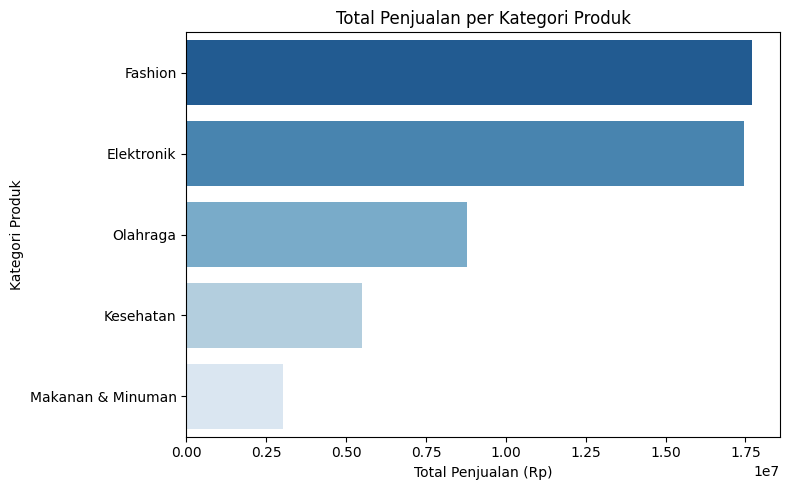

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (Rp)')
plt.ylabel('Kategori Produk')
plt.tight_layout()
plt.show()

**Jawaban Analisis 2**

1. Kategori dengan penjualan tertinggi dan terendah:

- Tertinggi: Fashion (Rp17.695.000), diikuti sangat tipis oleh Elektronik (Rp17.450.000).

- Terendah: Makanan & Minuman (Rp3.029.000).

2. Rekomendasi bisnis untuk manajer Nusantara Mart:

- Pertahankan performa kategori unggulan: Pastikan ketersediaan stok untuk Fashion dan Elektronik selalu aman serta perkuat promosinya karena keduanya menyumbang pendapatan terbesar perusahaan.

- Dorong penjualan kategori rendah: Buat paket bundling (paket hemat), diskon khusus, atau promo cross-selling (penawaran tambahan saat checkout) untuk meningkatkan minat beli pada kategori Makanan & Minuman dan Kesehatan.

--------

**Latihan 3: Visualisasi Tren dengan Line Chart**

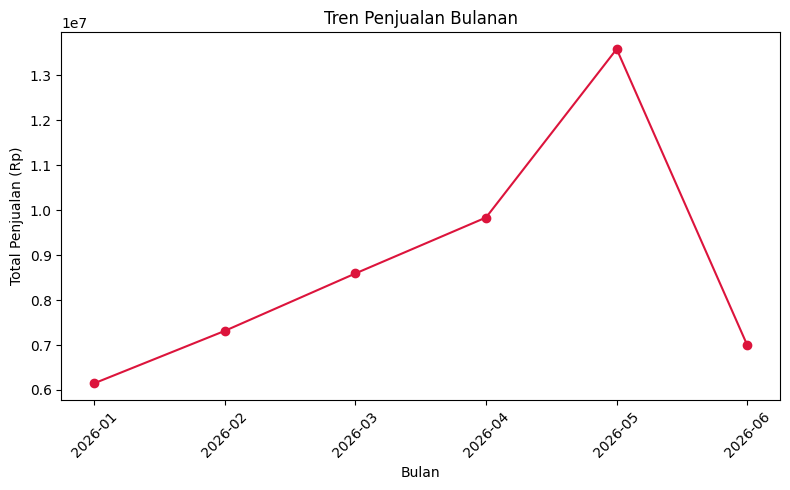

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Memuat dataset
df = pd.read_csv('penjualan_nusantaramart.csv')

# Mengubah format tanggal & mengelompokkan per bulan
df['tanggal'] = pd.to_datetime(df['tanggal'])
df['bulan'] = df['tanggal'].dt.to_period('M')
tren_bulanan = df.groupby('bulan')['total'].sum()

# Visualisasi Line Chart
plt.figure(figsize=(8,5))
plt.plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o', color='crimson')
plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rp)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Jawaban Analisis 3**

1. Bulan dengan penjualan tertinggi dan kemungkinan penyebabnya:

- Bulan tertinggi: Mei 2026 (2026-05) dengan total penjualan sebesar Rp13.585.000.

- Kemungkinan penyebab: Adanya promo besar-besaran (seperti promo tanggal kembar 5.5 atau promo tengah tahun), meningkatnya daya beli masyarakat, atau transaksi pembelian dalam jumlah besar (bulk order).

2. Pola tren penjualan (naik, turun, atau fluktuatif) dan penjelasannya:

- Pola tren: Fluktuatif (naik konsisten lalu turun tajam).

- Penjelasan: Penjualan meningkat stabil setiap bulan dari Januari (Rp6.147.000) hingga mencapai puncaknya di Mei (Rp13.585.000), kemudian mengalami penurunan drastis pada bulan Juni menjadi Rp6.992.000.

-------


**Latihan 4: Visualisasi Hubungan dengan Scatter Plot**

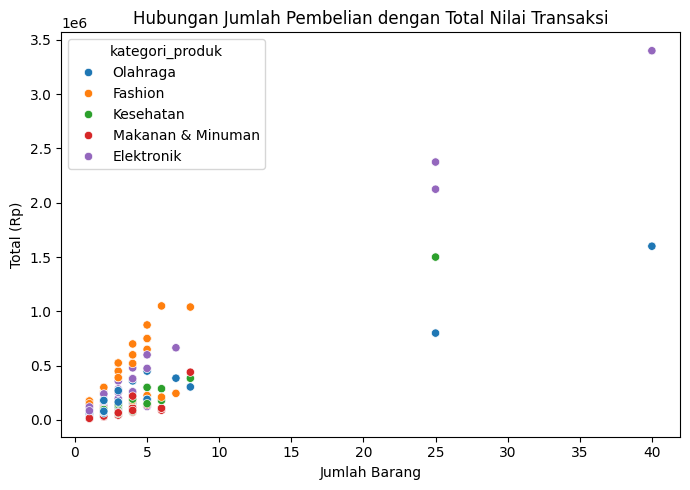

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat dataset
df = pd.read_csv('penjualan_nusantaramart.csv')

# Visualisasi Scatter Plot
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='jumlah', y='total', hue='kategori_produk')
plt.title('Hubungan Jumlah Pembelian dengan Total Nilai Transaksi')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total (Rp)')
plt.tight_layout()
plt.show()

**Jawaban Latihan 4**

- Pola hubungan antara jumlah barang dan total nilai transaksi:
Terdapat hubungan positif yang kuat (nilai korelasi $r \approx 0,85$). Semakin banyak jumlah barang yang dibeli (jumlah), semakin tinggi pula total nilai transaksinya (total), meskipun kemiringan polanya berbeda-beda tergantung harga satuan masing-masing kategori produk.

- Keberadaan titik data jauh dari pola umum (outlier) dan kategorinya:Ya, terdapat beberapa outlier yang jelas. Sebagian besar transaksi mengumpul pada pembelian 1 hingga 8 barang dengan total di bawah Rp1.050.000, namun ada 6 titik data yang terpisah jauh di bagian kanan/atas (pembelian berjumlah 25 dan 40 unit dengan nilai transaksi Rp800.000 hingga Rp3.400.000) yang berasal dari kategori Elektronik (nilai tertinggi hingga Rp3.400.000), Olahraga (Rp800.000 – Rp1.600.000), dan Kesehatan (Rp1.500.000).

---

**Latihan 5: Visualisasi Distribusi & Deteksi Outlier (Histogram & Boxplot)**

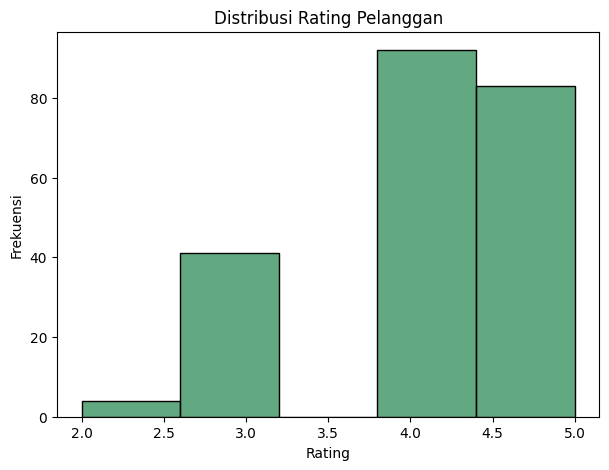

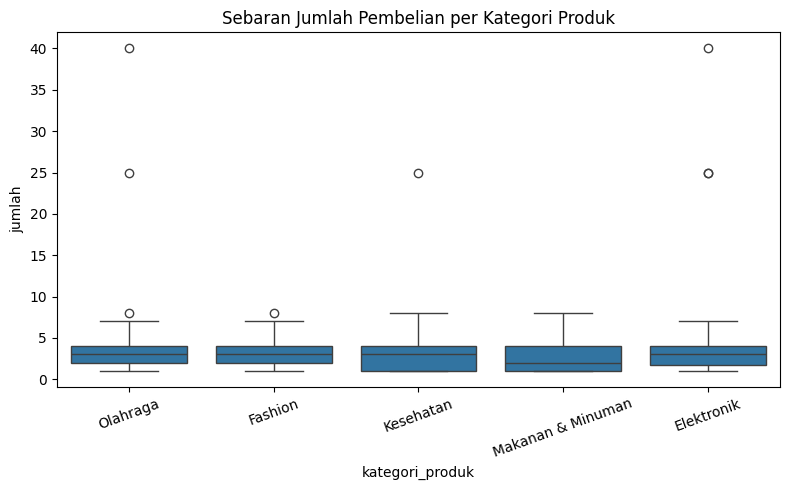

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat dataset
df = pd.read_csv('penjualan_nusantaramart.csv')

# Histogram distribusi rating pelanggan
plt.figure(figsize=(7,5))
sns.histplot(df['rating_pelanggan'], bins=5, color='seagreen')
plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating')
plt.ylabel('Frekuensi')
plt.show()

# Boxplot jumlah pembelian per kategori (deteksi outlier)
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='kategori_produk', y='jumlah')
plt.title('Sebaran Jumlah Pembelian per Kategori Produk')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Jawaban Analisis 5**

1. Bentuk distribusi rating pelanggan:
Distribusi rating pelanggan cenderung tinggi (miring ke kiri / left-skewed). Mayoritas pelanggan memberikan rating 4 (92 transaksi) dan rating 5 (83 transaksi)—mencakup hampir 80% dari total transaksi—sementara rating 3 hanya 41 transaksi, rating 2 hanya 4 transaksi, dan tidak ada rating 1.

2. Kategori produk yang memiliki outlier pada boxplot dan kemungkinan penyebabnya:

- Kategori yang memiliki outlier: Elektronik (jumlah pembelian 25 dan 40 unit), Olahraga (8, 25, dan 40 unit), Kesehatan (25 unit), serta Fashion (8 unit). Hanya kategori Makanan & Minuman yang tidak memiliki outlier.

- Kemungkinan penyebab: Pembelian dalam partai besar (bulk order) oleh reseller/dropshipper untuk dijual kembali, atau pengadaan barang untuk keperluan instansi/kantor/acara/komunitas (misalnya pembelian alat olahraga, perlengkapan kesehatan, atau aksesori elektronik secara massal).

---

**Tugas Analisis 6**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat & menyiapkan data
df = pd.read_csv('penjualan_nusantaramart.csv')
df['tanggal'] = pd.to_datetime(df['tanggal'])
df['bulan'] = df['tanggal'].dt.to_period('M')

total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)
tren_bulanan = df.groupby('bulan')['total'].sum()

# Dashboard 2x2 Subplot
fig, axes = plt.subplots(2, 2, figsize=(13,9))

sns.barplot(x=total_kategori.values, y=total_kategori.index, ax=axes[0,0])
axes[0,0].set_title('Total Penjualan per Kategori')

axes[0,1].plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o')
axes[0,1].set_title('Tren Penjualan Bulanan')

sns.histplot(df['rating_pelanggan'], bins=5, ax=axes[1,0])
axes[1,0].set_title('Distribusi Rating Pelanggan')

sns.boxplot(data=df, x='kategori_produk', y='jumlah', ax=axes[1,1])
axes[1,1].set_title('Sebaran Jumlah per Kategori')

plt.tight_layout()
plt.show()

**Jawaban Analisis 6**

- Keuntungan menyajikan grafik dalam satu dashboard:
Memberikan gambaran menyeluruh dalam satu layar tanpa perlu berpindah-pindah grafik, sehingga memudahkan perbandingan antar-metrik dan mempercepat pengambilan keputusan bisnis.

- Keputusan bisnis sebagai manajer Nusantara Mart:

1. Prioritaskan kategori unggulan: Jaga stok dan perkuat promosi pada Fashion (Rp17,69 juta) dan Elektronik (Rp17,45 juta), serta buat promo bundling untuk mengangkat Makanan & Minuman (Rp3,03 juta).

2. Stabilkan tren penjualan: Evaluasi penyebab penurunan di bulan Juni (Rp6,99 juta) setelah puncak di Mei (Rp13,58 juta), lalu adakan promo retensi pelanggan.

3. Sediakan paket grosir/reseller: Buat program khusus pembelian partai besar (outlier 25–40 unit) yang banyak terjadi pada kategori Elektronik dan Olahraga, sembari mempertahankan kualitas layanan (rating mayoritas 4–5).